In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import scrublet as scr
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob

sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [6,6]
plt.rcParams["pdf.fonttype"] = 42 # add pdf text as one piece instead of letter by letter

In [2]:
sb.set_palette('colorblind')

In [3]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [4]:
# figure directory
fig_path = '/home/jovyan/mount/gdrive/HSC/chenqu_jhub/'
sc.settings.figdir = fig_path

# Load data

## Pooled screen

In [5]:
pool=sc.read("write/pool_scvi_v2.h5ad")

In [12]:
pool_d18 = pool[pool.obs['HSC_days']==0]

In [13]:
pool_d18_ctl = pool_d18[pool_d18.obs['TF_calling'].isna()]

In [14]:
tf_counts = pool_d18.obs["TF_calling"].value_counts()
tf_select = tf_counts[tf_counts > 9].index.tolist() # keep the TFs with at least 10 cells
tf_counts[tf_counts > 9]
tf_selected = sorted(tf_counts[tf_counts > 9].index.tolist())
tf_selected = [gene for gene in tf_selected if gene !='MULTIHIT'] # remove MULTIHIT
tf_selected = [gene for gene in tf_selected if gene in pool_d18.var_names]

In [15]:
len(tf_selected)

360

In [16]:
from scipy import sparse

# keep only genes present in both objects
genes = [
    g for g in tf_selected
    if g in pool_d18.var_names and g in pool_d18_ctl.var_names
]

# subset once
X_pool = pool_d18[:, genes].X
X_ctl = pool_d18_ctl[:, genes].X

# CSC is efficient for extracting individual gene columns
if sparse.issparse(X_pool):
    X_pool = X_pool.tocsc()

if sparse.issparse(X_ctl):
    X_ctl = X_ctl.tocsc()


rows = []

tf_calling = pool_d18.obs["TF_calling"].to_numpy()

for j, gene in enumerate(genes):

    # cells carrying this TF barcode
    tf_mask = tf_calling == gene

    # barcode cells
    x_barcode = X_pool[tf_mask, j]

    if sparse.issparse(x_barcode):
        x_barcode = x_barcode.toarray().ravel()
    else:
        x_barcode = np.asarray(x_barcode).ravel()

    # control cells
    x_ctl = X_ctl[:, j]

    if sparse.issparse(x_ctl):
        x_ctl = x_ctl.toarray().ravel()
    else:
        x_ctl = np.asarray(x_ctl).ravel()

    rows.append({
        "gene": gene,
        "barcode_cells": len(x_barcode),
        "no_barcode_cells": len(x_ctl),

        "barcode_mean": (
            x_barcode.mean()
            if len(x_barcode) > 0 else np.nan
        ),

        "barcode_variance": (
            x_barcode.var(ddof=1)
            if len(x_barcode) > 1 else np.nan
        ),

        "no_barcode_mean": (
            x_ctl.mean()
            if len(x_ctl) > 0 else np.nan
        ),

        "no_barcode_variance": (
            x_ctl.var(ddof=1)
            if len(x_ctl) > 1 else np.nan
        ),
    })


tf_summary = pd.DataFrame(rows)

tf_summary["mean_difference"] = (
    tf_summary["barcode_mean"]
    - tf_summary["no_barcode_mean"]
)

In [17]:
#tf_summary.to_csv('csv/pooled_screen_D18_TF_expression.csv')
tf_summary.to_csv('csv/pooled_screen_D0_TF_expression.csv')

# Plot TF overexpression 

In [8]:
lenti_d7 = pd.read_csv('csv/10x_raw_87tf_vs_no_barcode_summary.csv')
# restrict to TFs with at least 10 cells
lenti_d7 = lenti_d7.loc[lenti_d7['barcode_cells']>9,:]

In [9]:
np.mean(lenti_d7['mean_difference'])

np.float64(0.024736328980705876)

In [10]:
rmce_pool_d0 = pd.read_csv('csv/pooled_screen_D0_TF_expression.csv')
rmce_pool_d18 = pd.read_csv('csv/pooled_screen_D18_TF_expression.csv')

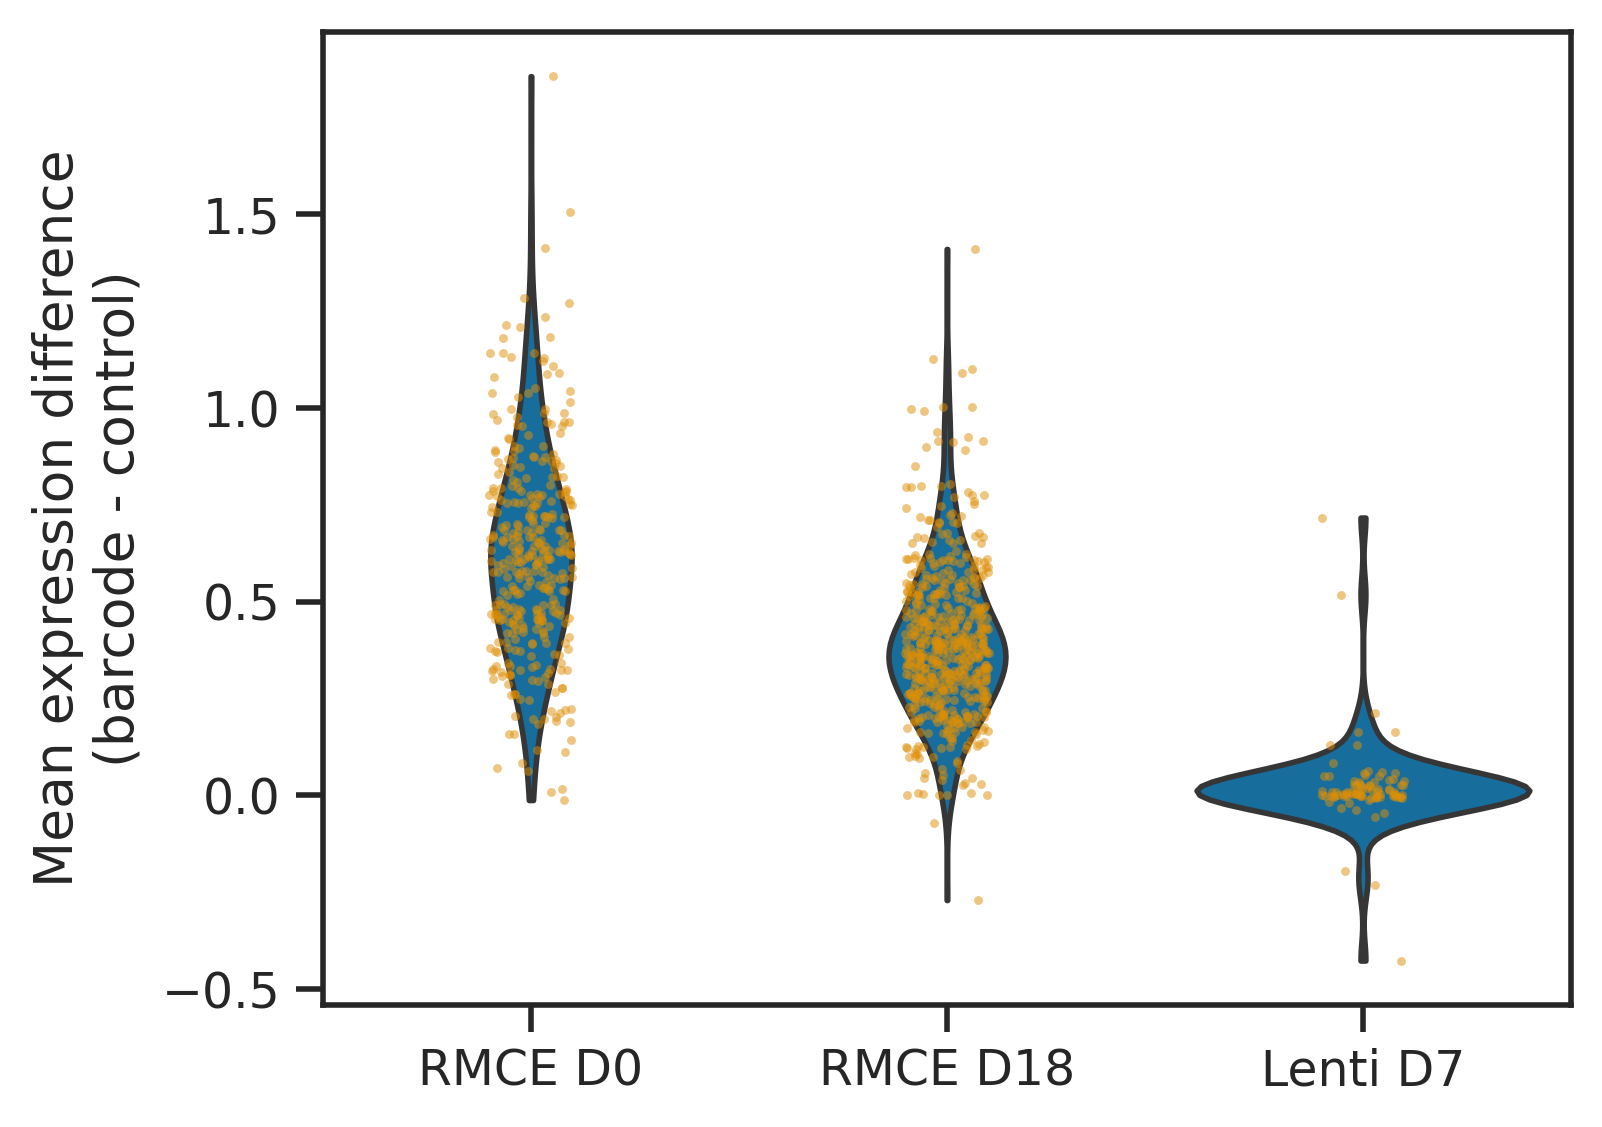

In [12]:
sb.set_theme(style="ticks")
palette = sb.color_palette('colorblind')

plot_df = pd.concat([
    rcme_pool_d0.assign(dataset='RMCE D0'),
    rcme_pool_d18.assign(dataset='RMCE D18'),
    lenti_d7.assign(dataset="Lenti D7"),
], ignore_index=True)

plt.figure(figsize=(5, 4))

sb.violinplot(
    data=plot_df,
    x="dataset",
    y="mean_difference",
    inner=None,
    cut=0,
    color=palette[0]
)

sb.stripplot(
    data=plot_df,
    x="dataset",
    y="mean_difference",
    jitter=True,
    alpha=0.5,
    size=2,
    color=palette[1]
)

#plt.axhline(0, color="grey", linestyle="--", linewidth=1)

plt.xlabel("")
plt.ylabel("Mean expression difference\n(barcode - control)")

#sb.despine()
plt.savefig(
    "figure/TF_mean_expression_difference_stripplot.pdf",
    bbox_inches="tight"
)

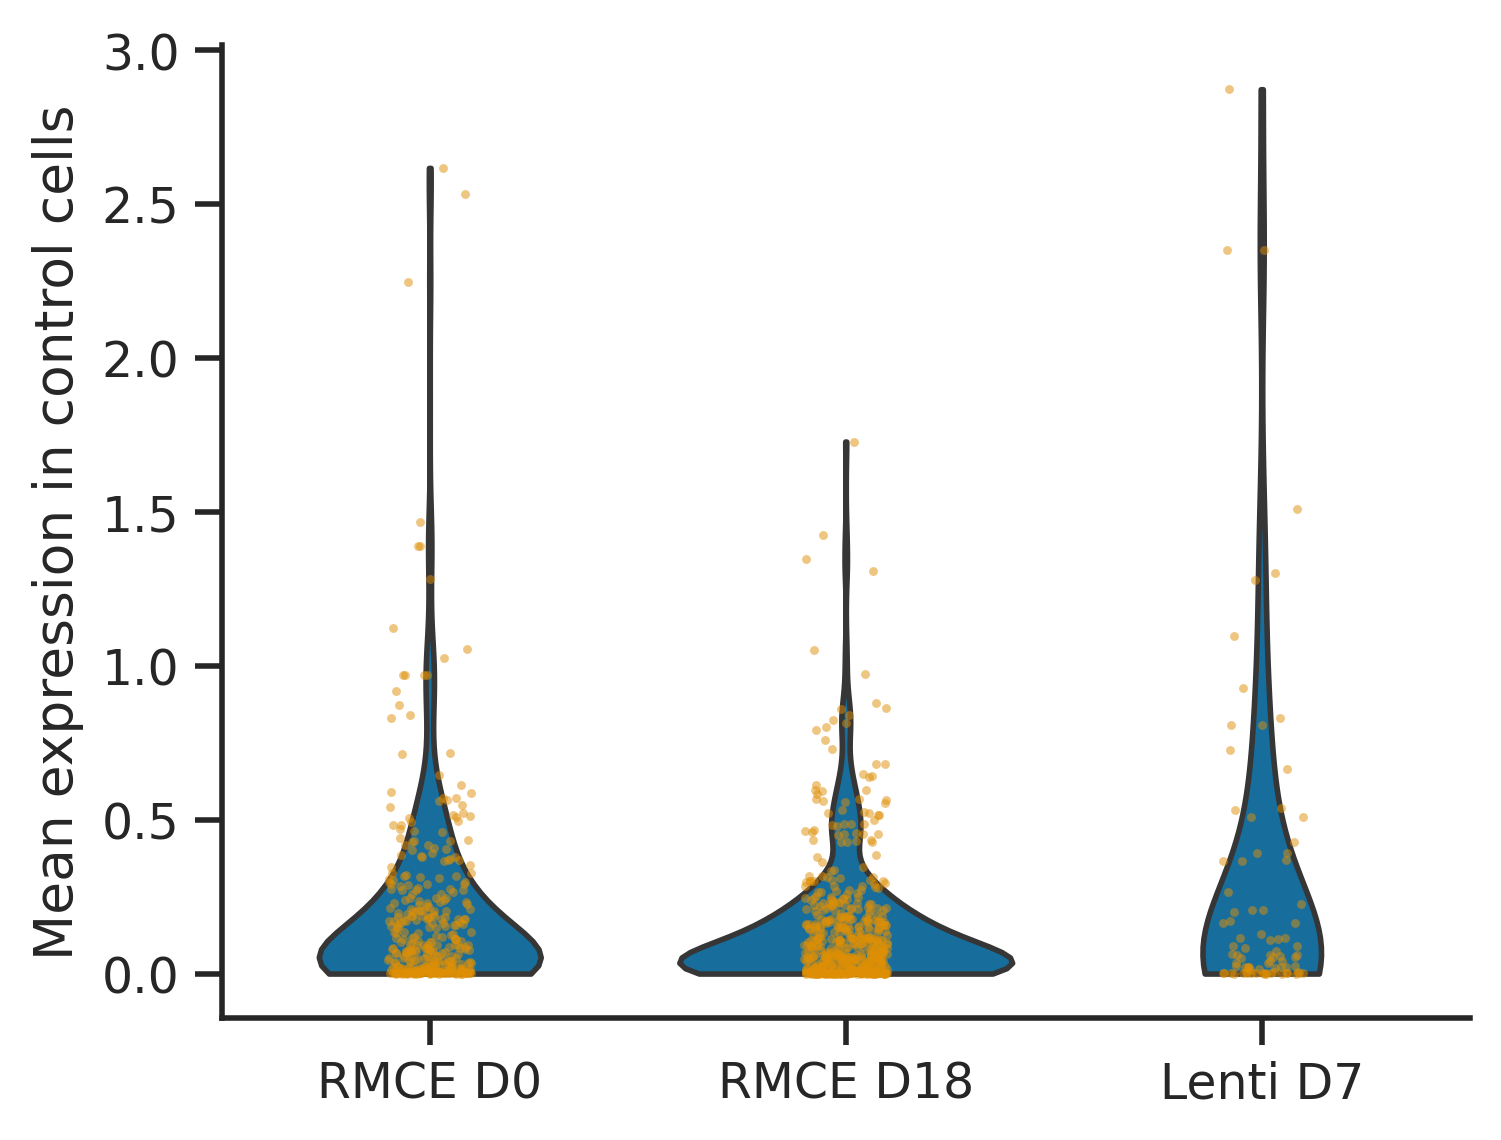

In [13]:
plt.figure(figsize=(5, 4))

sb.violinplot(
    data=plot_df,
    x="dataset",
    y="no_barcode_mean",
    inner=None,
    cut=0,
    color=palette[0]
)

sb.stripplot(
    data=plot_df,
    x="dataset",
    y="no_barcode_mean",
    jitter=True,
    alpha=0.5,
    size=2,
    color=palette[1]
)

plt.xlabel("")
plt.ylabel("Mean expression in control cells")

sb.despine()
plt.show()

Look at variance - Not used in the end

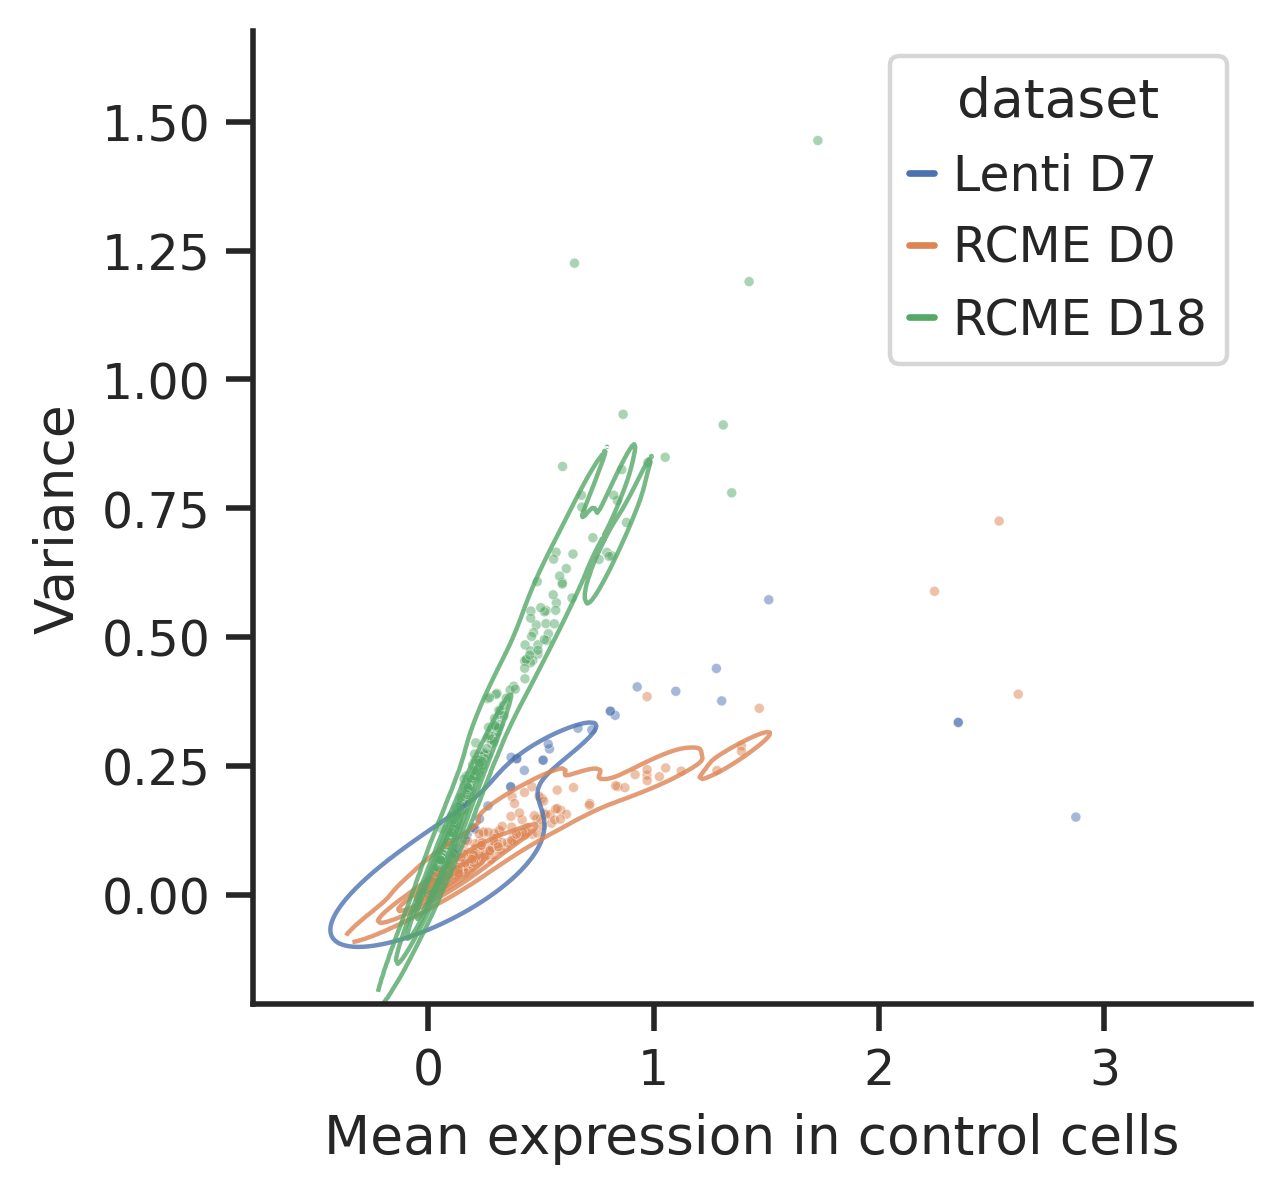

In [10]:
sb.set_theme(style="ticks")

plt.figure(figsize=(4, 4))

# KDE contours
sb.kdeplot(
    data=plot_df,
    x="no_barcode_mean",
    y="no_barcode_variance",
    hue="dataset",
    levels=5,
    linewidths=1,
    alpha=0.8
)

# individual TFs
sb.scatterplot(
    data=plot_df,
    x="no_barcode_mean",
    y="no_barcode_variance",
    hue="dataset",
    alpha=0.5,
    s=5,
    legend=False
)
plt.xlabel("Mean expression in control cells")
plt.ylabel("Variance")

sb.despine()
plt.show()

It is almost a linear relationship, but the slope is different across different experiments. This might be mainly influenced by different sequencing depth in different experiments.
Hence, I do not think we can compare variance in barcoded cells across experiments.

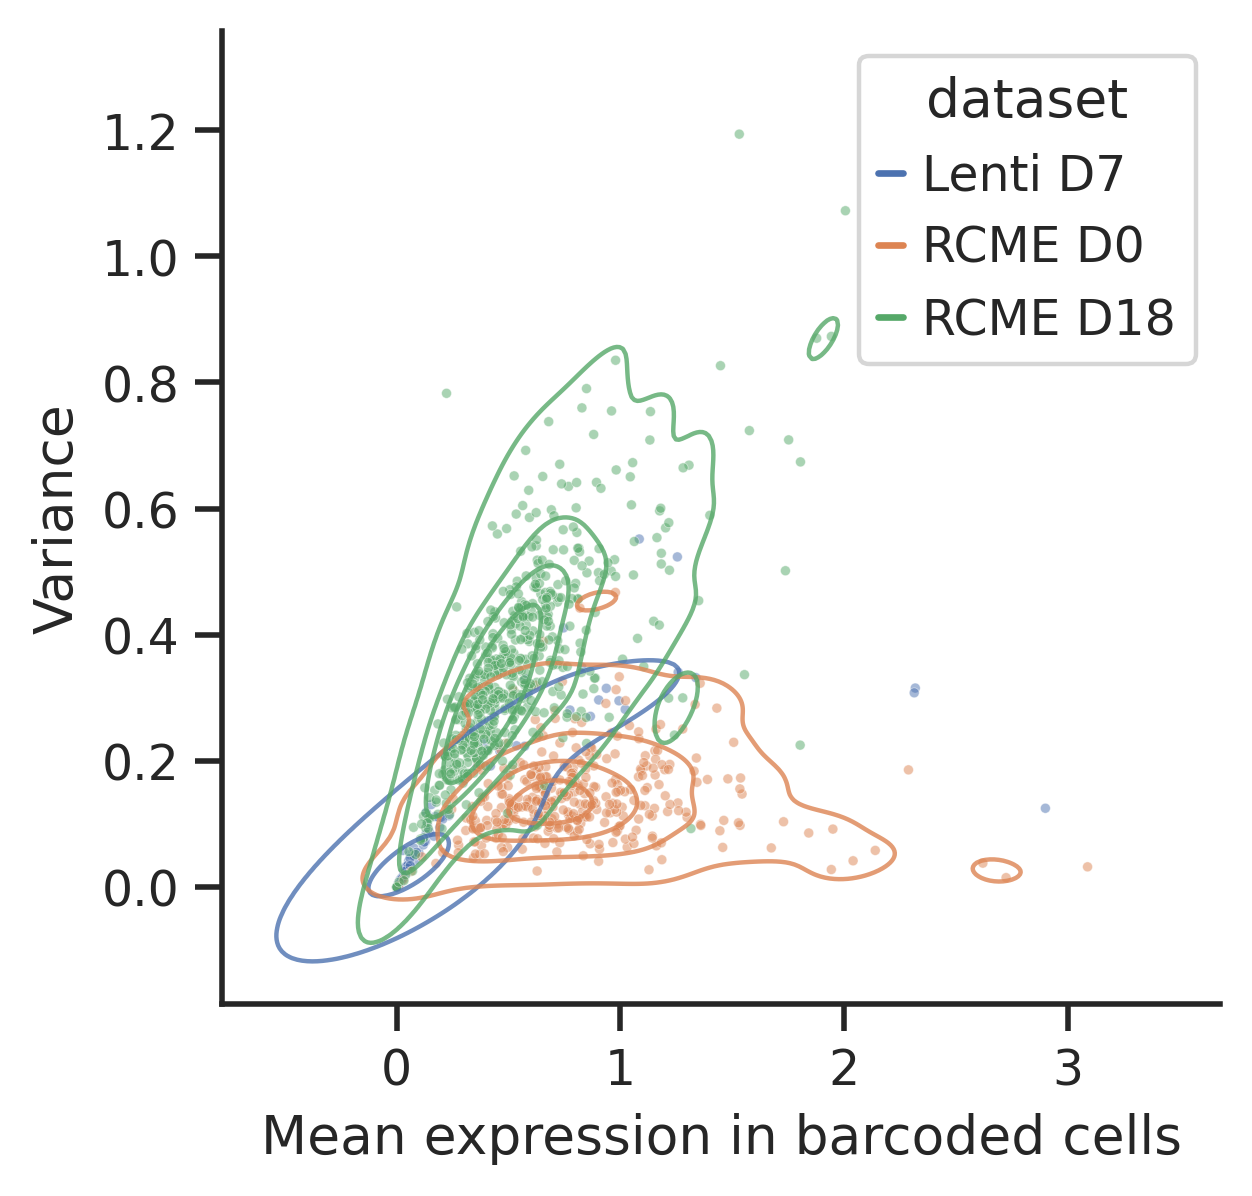

In [11]:
sb.set_theme(style="ticks")

plt.figure(figsize=(4, 4))

# KDE contours
sb.kdeplot(
    data=plot_df,
    x="barcode_mean",
    y="barcode_variance",
    hue="dataset",
    levels=5,
    linewidths=1,
    alpha=0.8
)

# individual TFs
sb.scatterplot(
    data=plot_df,
    x="barcode_mean",
    y="barcode_variance",
    hue="dataset",
    alpha=0.5,
    s=5,
    legend=False
)
plt.xlabel("Mean expression in barcoded cells")
plt.ylabel("Variance")

sb.despine()
plt.show()

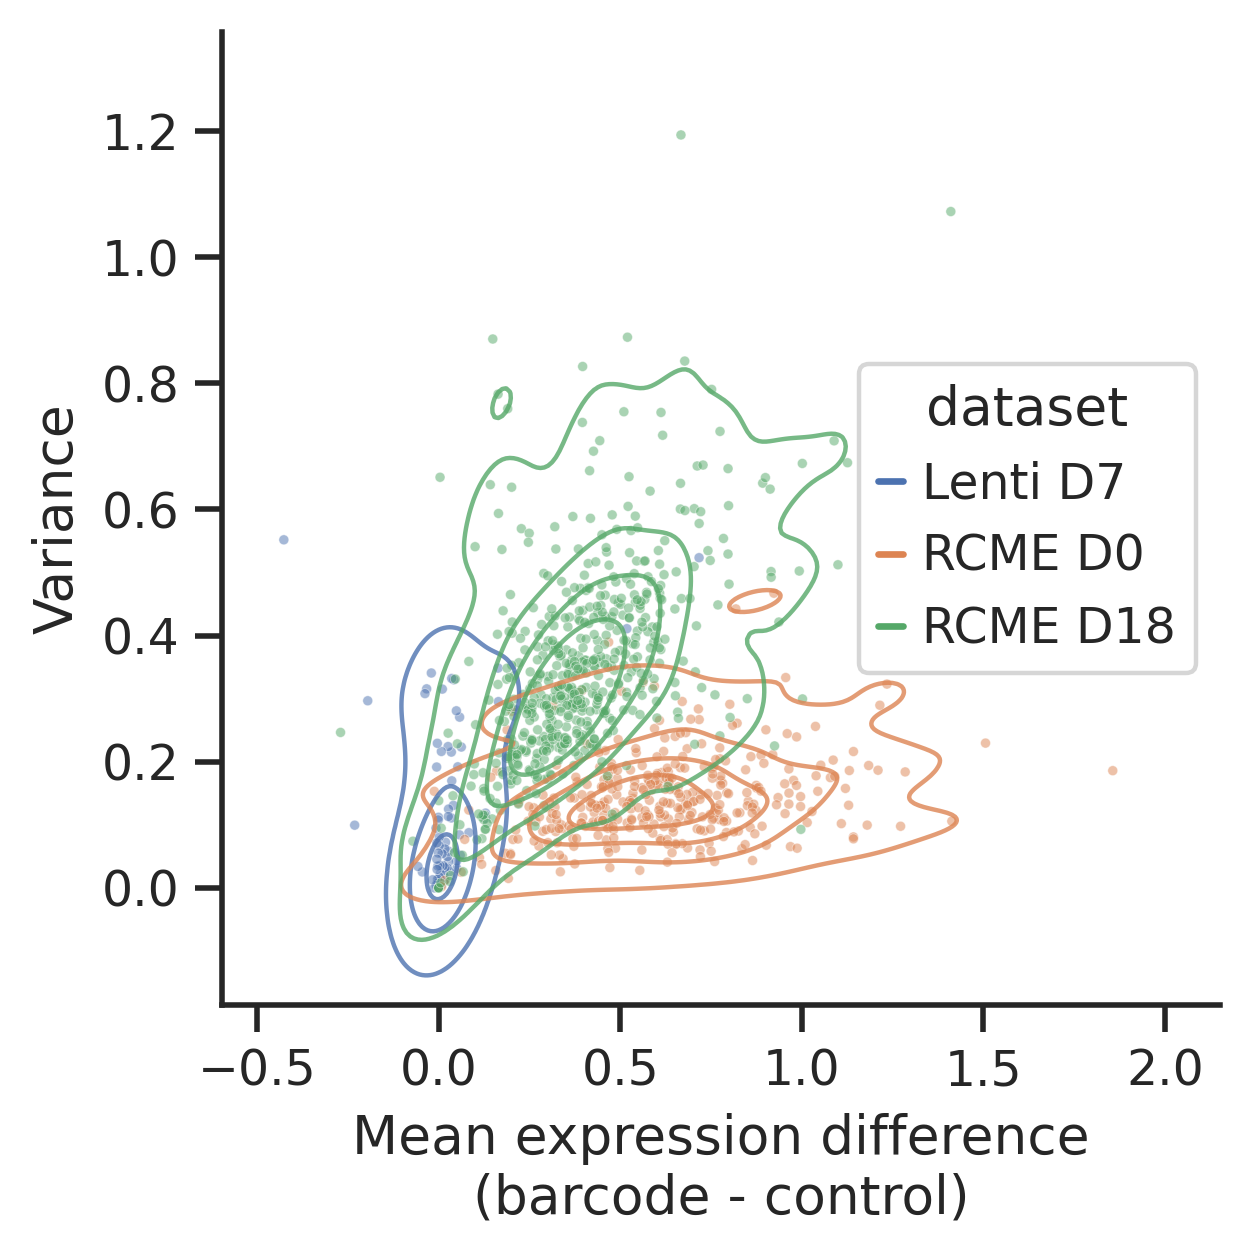

In [12]:
sb.set_theme(style="ticks")

plt.figure(figsize=(4, 4))

# KDE contours
sb.kdeplot(
    data=plot_df,
    x="mean_difference",
    y="barcode_variance",
    hue="dataset",
    levels=5,
    linewidths=1,
    alpha=0.8
)

# individual TFs
sb.scatterplot(
    data=plot_df,
    x="mean_difference",
    y="barcode_variance",
    hue="dataset",
    alpha=0.5,
    s=5,
    legend=False
)
plt.xlabel("Mean expression difference\n(barcode - control)")
plt.ylabel("Variance")

sb.despine()
plt.show()